<a href="https://colab.research.google.com/github/hoangvvthu/machine_learning/blob/main/_downloads/cifar10_Model1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phân loại ảnh CIFAR-10 — Model 1
Kiến trúc đầu vào: Mạng CNN nhận ảnh màu RGB có kích thước 32 × 32 pixel, gồm 3 kênh màu (Red, Green, Blue). Tensor đầu vào có dạng (C, H, W) = (3, 32, 32). Từ đầu vào này, tiến hành thiết kế các lớp Convolution, Pooling, phép cộng Tensor, phép nối Tensor và Fully Connected theo yêu cầu của từng mô hình.  
# Yêu cầu:  
Thiết kế thêm ít nhất 10 conv3x3(),  
01 maxpooling(.),  
02 torch.cat(.),  
02 cộng 2 tensors,   
03 fully connected layer (FC(.)).   
Số lượng parameters từ khoảng 5M đến 10M.


## 1. Nạp và quan sát dữ liệu CIFAR-10


In [1]:
%matplotlib inline

In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
torch.manual_seed(42)
model_number = 1

In [3]:
from google.colab import drive
drive.mount('/content/drive')

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

data_path = '/content/drive/MyDrive/CIFAR10'

trainset = torchvision.datasets.CIFAR10(root=data_path, train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=4,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root=data_path, train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=4,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Mounted at /content/drive


 frog plane  deer   car


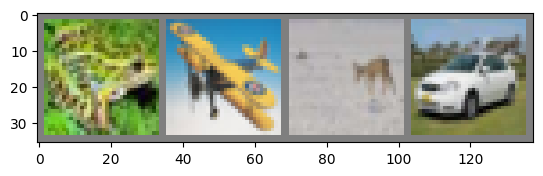

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join('%5s' % classes[labels[j]] for j in range(4)))

## 2. Khai báo mạng CNN — Model 1

10 Conv 3×3, 1 MaxPool, 2 ADD, 2 CAT và 3 FC. `__init__()` khai báo lớp; `forward()` xác định đường đi của tensor. Dùng `x` cho luồng đang xử lý, `x1`/`x2` để giữ nhánh cần dùng lại.

`[B,C,H,W]`: batch, kênh, chiều cao, chiều rộng. **ADD** cộng tensor cùng shape; **CAT** nối kênh; **SPLIT** chia kênh. Flatten trải C×H×W thành một vector cho mỗi ảnh.

| Cụm kiến trúc | Luồng đặc trưng | Shape đầu ra |
|---|---|---|
| Khởi đầu | Conv1: 3 → 32 | `[B, 32, 32, 32]` |
| Rẽ hai nhánh | Conv2 / Conv3: 32 → 64 | Mỗi nhánh `[B, 64, 32, 32]` |
| ADD1 | Conv2 + Conv3 | `[B, 64, 32, 32]` |
| Hai nhánh tiếp theo | Conv4→Conv5; Conv6→Conv7 | Mỗi nhánh `[B, 128, 16, 16]` |
| ADD2 | Conv5 + Conv7 | `[B, 128, 16, 16]` |
| Conv8 / CAT1 | 128 → 64; 128 + 64 | `[B, 192, 16, 16]` |
| Conv9→Conv10 / CAT2 | 64→128→256; 192 + 256 | `[B, 448, 16, 16]` |
| MaxPool + Flatten | 16×16 → 8×8; 448×8×8 | `[B, 28672]` |
| Ba lớp FC | 28672 → 256 → 128 → 10 | `[B, 10]` |

Ba model đều dùng cùng cách khởi tạo: Kaiming cho Conv, mặc định cho FC. FC cuối tạo 10 logits, không qua ReLU hoặc Softmax trước `CrossEntropyLoss`.


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        # Conv khai báo số kênh vào/ra, kernel, stride, padding; forward xác định đường nối.
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv4 = nn.Conv2d(64, 96, kernel_size=3, stride=2, padding=1)
        self.conv5 = nn.Conv2d(96, 128, kernel_size=3, stride=1, padding=1)
        self.conv6 = nn.Conv2d(64, 96, kernel_size=3, stride=2, padding=1)
        self.conv7 = nn.Conv2d(96, 128, kernel_size=3, stride=1, padding=1)
        self.conv8 = nn.Conv2d(128, 64, kernel_size=3, stride=1, padding=1)
        self.conv9 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.conv10 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)
        # Cùng module MaxPool có thể được gọi ở nhiều vị trí trong forward.
        self.pool = nn.MaxPool2d(2, 2)
        # FC1 nhận vector Flatten; lớp FC cuối tạo 10 logits.
        self.fc1 = nn.Linear(448 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

        # ReLU: khởi tạo Conv bằng Kaiming để tín hiệu qua mạng sâu ổn định hơn.
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        # KHỐI 1: Ảnh RGB -> Conv1: [B,3,32,32] -> [B,32,32,32].
        x = F.relu(self.conv1(x))

        # KHỐI 2: Hai Conv cùng nhận Conv1; giữ Conv2 trong x1 cho Conv4.
        x1 = F.relu(self.conv2(x))             # Conv2: [B,64,32,32].
        x = F.relu(self.conv3(x))              # Conv3: [B,64,32,32].
        x = x1 + x                            # ADD1: [B,64,32,32].

        # KHỐI 3: Conv4 lấy Conv2 (x1); Conv6 lấy ADD1 (x), đúng draw.io.
        x1 = F.relu(self.conv4(x1))            # 64 -> 96 kênh; H,W: 32 -> 16.
        x1 = F.relu(self.conv5(x1))            # Conv5: 96 -> 128.
        x = F.relu(self.conv6(x))              # ADD1 -> Conv6: 64 -> 96.
        x = F.relu(self.conv7(x))              # Conv7: 96 -> 128.
        x = x1 + x                            # ADD2: [B,128,16,16].

        # KHỐI 4: Chỉ giữ tensor cần ghép lại trong x1; x tiếp tục qua Conv.
        x1 = x                                # Giữ ADD2, không thay đổi tensor.
        x = F.relu(self.conv8(x))              # Conv8: [B,64,16,16].
        x1 = torch.cat((x1, x), dim=1)         # CAT1 = ADD2 128 + Conv8 64 = 192.
        x = F.relu(self.conv9(x))              # Conv9 lấy Conv8: 64 -> 128.
        x = F.relu(self.conv10(x))             # Conv10: 128 -> 256.
        x = torch.cat((x1, x), dim=1)          # CAT2 = CAT1 192 + Conv10 256 = 448.

        # KHỐI 5: MaxPool -> Flatten -> ba lớp FC.
        x = self.pool(x)                      # [B,448,16,16] -> [B,448,8,8].
        x = torch.flatten(x, 1)               # 448*8*8 = 28672 đặc trưng/ảnh.
        x = F.relu(self.fc1(x))               # 28672 -> 256.
        x = F.relu(self.fc2(x))               # 256 -> 128.
        x = self.fc3(x)                       # [B,10]: 10 logits.
        return x

net = Net()
from torchsummary import summary
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = net.to(device)
summary(net, (3, 32, 32), device=device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 32, 32]             896
            Conv2d-2           [-1, 64, 32, 32]          18,496
            Conv2d-3           [-1, 64, 32, 32]          18,496
            Conv2d-4           [-1, 96, 16, 16]          55,392
            Conv2d-5          [-1, 128, 16, 16]         110,720
            Conv2d-6           [-1, 96, 16, 16]          55,392
            Conv2d-7          [-1, 128, 16, 16]         110,720
            Conv2d-8           [-1, 64, 16, 16]          73,792
            Conv2d-9          [-1, 128, 16, 16]          73,856
           Conv2d-10          [-1, 256, 16, 16]         295,168
        MaxPool2d-11            [-1, 448, 8, 8]               0
           Linear-12                  [-1, 256]       7,340,288
           Linear-13                  [-1, 128]          32,896
           Linear-14                   

## 3. Hàm mất mát và bộ tối ưu

`CrossEntropyLoss` so sánh logits với nhãn thật. Cả ba model dùng SGD với `lr=0.001`, `momentum=0.9`, `weight_decay=0`.


In [6]:
learning_rate = 0.001
momentum = 0.9
weight_decay = 0.0

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    net.parameters(), lr=learning_rate, momentum=momentum, weight_decay=weight_decay
)

print("Loss function:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", learning_rate)
print("Momentum:", momentum)
print("Weight decay:", weight_decay)

Loss function: CrossEntropyLoss
Optimizer: SGD
Learning rate: 0.001
Momentum: 0.9
Weight decay: 0.0


## 4. Huấn luyện mạng

Mỗi batch: **xóa gradient → forward → tính loss → backward → cập nhật weights**. Chạy 10 epochs. Loss/accuracy dưới đây được tính trên train trong lúc model học.


In [7]:
num_epochs = 10
train_loss_history = []
train_accuracy_history = []

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in trainloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        outputs = net(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct_predictions += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = 100.0 * correct_predictions / total_samples
    train_loss_history.append(epoch_loss)
    train_accuracy_history.append(epoch_accuracy)
    print(f"Epoch [{epoch + 1}/{num_epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_accuracy:.2f}%")

print("Finished Training")

Epoch [1/10] - Loss: 1.4208 - Accuracy: 48.22%
Epoch [2/10] - Loss: 0.9499 - Accuracy: 66.50%
Epoch [3/10] - Loss: 0.7370 - Accuracy: 74.29%
Epoch [4/10] - Loss: 0.5825 - Accuracy: 79.60%
Epoch [5/10] - Loss: 0.4479 - Accuracy: 84.38%
Epoch [6/10] - Loss: 0.3397 - Accuracy: 88.17%
Epoch [7/10] - Loss: 0.2727 - Accuracy: 90.41%
Epoch [8/10] - Loss: 0.2139 - Accuracy: 92.61%
Epoch [9/10] - Loss: 0.1722 - Accuracy: 93.93%
Epoch [10/10] - Loss: 0.1412 - Accuracy: 95.08%
Finished Training


### Biểu đồ huấn luyện

Theo dõi loss và accuracy theo epoch; kết quả test được tính riêng ở phần 5.


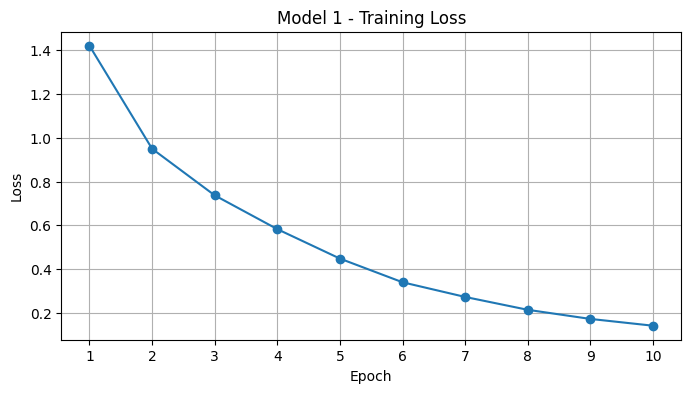

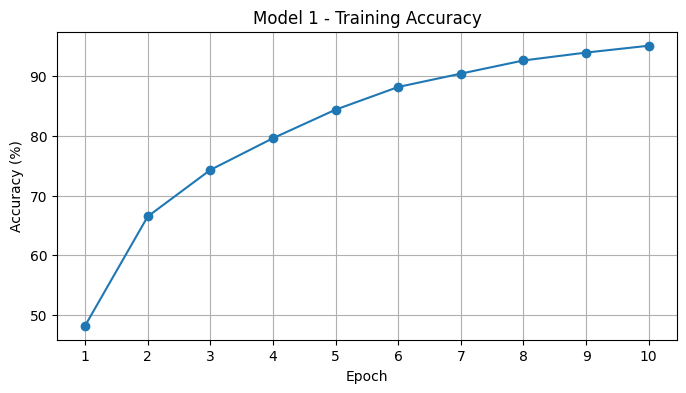

In [8]:
epochs = range(1, len(train_loss_history) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_loss_history, marker="o")
plt.title(f"Model {model_number} - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_accuracy_history, marker="o")
plt.title(f"Model {model_number} - Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(list(epochs))
plt.grid(True)
plt.show()

## 5. Kiểm tra trên dữ liệu test

Xem nhãn thật và dự đoán của một batch. Mỗi ảnh có 10 logits; `argmax(dim=1)` chọn lớp có điểm lớn nhất.


Ground truth: cat ship ship plane
Predicted:    cat ship ship ship


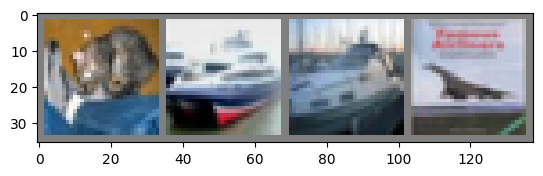

In [10]:
test_images, test_labels = next(iter(testloader))
imshow(torchvision.utils.make_grid(test_images))

net.eval()
with torch.no_grad():
    test_outputs = net(test_images.to(device))
predicted_classes = test_outputs.argmax(dim=1).cpu()

print("Ground truth:", " ".join(classes[label.item()] for label in test_labels))
print("Predicted:   ", " ".join(classes[label.item()] for label in predicted_classes))

### 5.1. Đánh giá toàn bộ 10.000 ảnh test

`eval()` đặt chế độ đánh giá; `no_grad()` tắt tính gradient. Phần này không cập nhật weights.


In [11]:
net.eval()
running_test_loss = 0.0
correct_test_predictions = 0
total_test_samples = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = net(images)
        loss = criterion(outputs, labels)
        running_test_loss += loss.item() * labels.size(0)
        correct_test_predictions += (outputs.argmax(dim=1) == labels).sum().item()
        total_test_samples += labels.size(0)

test_loss = running_test_loss / total_test_samples
test_accuracy = 100.0 * correct_test_predictions / total_test_samples
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 1.3664
Test Accuracy: 72.35%


### 5.2. Kết quả từng lớp

Mỗi lớp test có 1.000 ảnh. Tỷ lệ dưới đây là số nhận đúng chia cho số ảnh có nhãn thật thuộc lớp đó.


In [12]:
class_correct = [0] * len(classes)
class_total = [0] * len(classes)

net.eval()
with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        predictions = net(images).argmax(dim=1)
        for label, prediction in zip(labels.cpu(), predictions.cpu()):
            index = label.item()
            class_total[index] += 1
            class_correct[index] += int(prediction.item() == index)

class_accuracy = []
for index, name in enumerate(classes):
    accuracy = 100.0 * class_correct[index] / class_total[index]
    class_accuracy.append(accuracy)
    print(f"{name:>10}: {accuracy:6.2f}% ({class_correct[index]}/{class_total[index]})")

     plane:  77.20% (772/1000)
       car:  74.10% (741/1000)
      bird:  58.50% (585/1000)
       cat:  63.20% (632/1000)
      deer:  70.70% (707/1000)
       dog:  59.00% (590/1000)
      frog:  72.60% (726/1000)
     horse:  82.70% (827/1000)
      ship:  84.80% (848/1000)
     truck:  80.70% (807/1000)


### 5.3. Tổng kết

Số liệu được lấy từ các biến vừa tính. Train Accuracy cao chưa bảo đảm Test Accuracy cao; kết quả có thể thay đổi giữa các lần chạy.


In [13]:
total_params = sum(parameter.numel() for parameter in net.parameters())
best_class = max(range(len(classes)), key=lambda index: class_accuracy[index])
worst_class = min(range(len(classes)), key=lambda index: class_accuracy[index])

print(f"===== Model {model_number} Summary =====")
print(f"Total parameters: {total_params:,}")
print(f"Completed epochs: {len(train_loss_history)}")
print(f"Final training loss: {train_loss_history[-1]:.4f}")
print(f"Final training accuracy: {train_accuracy_history[-1]:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2f}%")
print(f"Train-test accuracy gap: {train_accuracy_history[-1] - test_accuracy:.2f} percentage points")
print(f"Best class: {classes[best_class]} ({class_accuracy[best_class]:.2f}%)")
print(f"Lowest class: {classes[worst_class]} ({class_accuracy[worst_class]:.2f}%)")


===== Model 1 Summary =====
Total parameters: 8,187,402
Completed epochs: 10
Final training loss: 0.1412
Final training accuracy: 95.08%
Test loss: 1.3664
Test accuracy: 72.35%
Train-test accuracy gap: 22.73 percentage points
Best class: ship (84.80%)
Lowest class: bird (58.50%)
